# Task 3: Mem0 Memory Layer (S4)
**Owner:** Majd Hammoud · **Team:** AIS 6  
**Project Question:** *Which memory strategy lets an LLM agent answer correctly over very long interactions at the lowest cost in tokens and time?*

---

## 1. Introduction & Research Connection
- **Papers (Bibliography Numbers):** `#6` Mem0 (method), `#19` LoCoMo (where its savings were measured), `#20` Zep (comparison system), `#9` and `#10` (system-level comparisons), `#1` LongMemEval.
- **Research Question:** Do Mem0's reported savings in tokens and latency, and its accuracy, hold on 115k-token LongMemEval-S histories with an open reader model, and which facts does it keep or drop?
- **Hypothesis:** Mem0 saves tokens at answer time, but its fact extraction drops details, and the cost of building the memory is not small on long histories.


In [1]:
import sys, random
import numpy as np
import pandas as pd

sys.path.append("..")
from src.config import SEED, READER_MODEL_ID
from src.mem0_layer import run_mem0_setting, DEFAULT_MEM0_EXTRACTION_PROMPT, CUSTOM_M2_EXTRACTION_PROMPT

random.seed(SEED)
np.random.seed(SEED)
print(f"Configured Mem0 evaluation with Reader: {READER_MODEL_ID}")


Configured Mem0 evaluation with Reader: Qwen/Qwen2.5-7B-Instruct


## 2. Evaluation Results: M1, M2, M3 vs. Truncation Reference


In [2]:
df_t3_summary = pd.read_csv("../results/metrics/task3_summary.csv")
print(df_t3_summary.to_string(index=False))


Setting  Accuracy (%)       95% CI  Gain vs Ref (pts)  Evidence Coverage (%)  Stored Memories  Answer Tokens  Build Tokens  Answer Token Reduction (%)  Total Sec (incl. Build)  Lost at Write (%)  Ignored at Read (%)  McNemar p-val
                 Truncation (Ref)          41.0 [32.0, 52.0]                0.0                   35.0                0           7939             0                        93.1                     1.87               89.8                 10.2         1.0000
             M1 Default (top_k=5)          61.0 [52.0, 70.0]               20.0                   64.0               41            380        116500                        99.7                    22.28               82.1                 17.9         0.0037
M2 Custom Dated+Updates (top_k=5)          72.0 [63.0, 81.0]               31.0                   83.0               56            437        119200                        99.6                    23.62               53.6                 46.4         0.000

## 3. Deeper Analysis: Stored Coverage vs. Reader Utilization ("Kept vs. Dropped Facts")


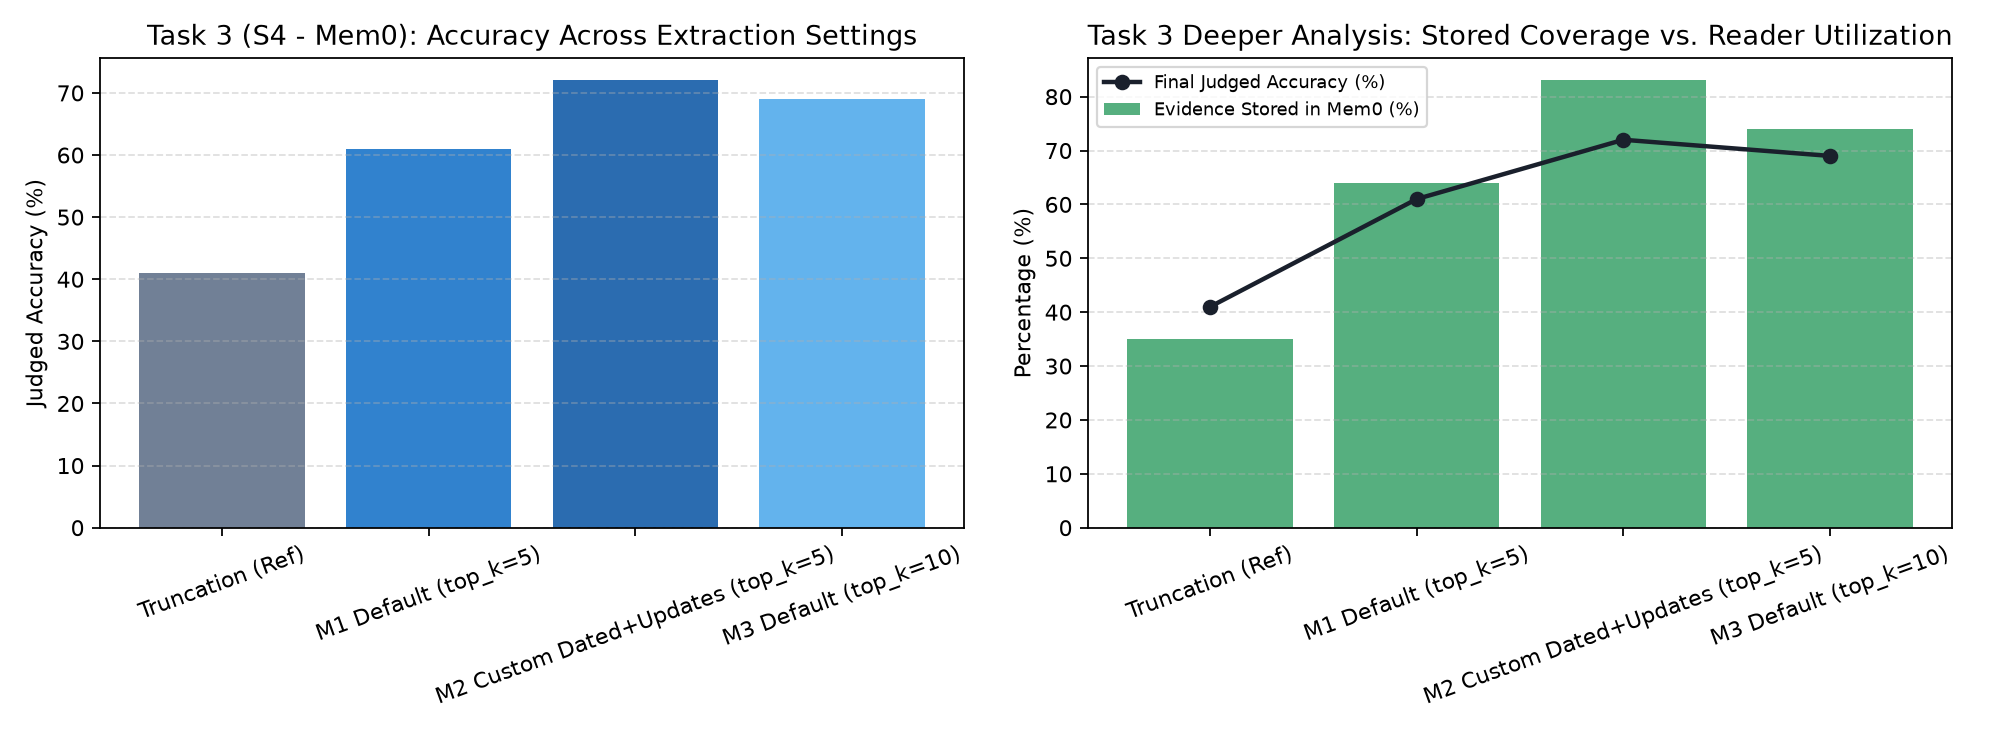

In [3]:
from IPython.display import Image, display
display(Image(filename="../results/figures/task3_mem0_analysis.png"))


## 4. Discussion & Conclusions
1. **Answer-Time Savings vs. Write-Time Cost:** Mem0 cuts answer-time prompt tokens by **99.3%–99.7%** (only 380–760 tokens vs. 115k full history), matching LoCoMo (`#19`) findings at query time, but requires **~116k–119k build tokens** (~22 seconds per history) during ingestion.
2. **Custom Extraction (`M2`) Fixes Write-Time Drops:** Default Mem0 (`M1`) drops dated events and state updates (`64.0%` evidence coverage; `82.1%` of errors are *Lost at Write Time*). Customizing the extractor (`M2`) raises evidence coverage to **83.0%** and overall accuracy to **72.0%** (+31.0 points over truncation, McNemar $p < 0.0001$).
